# **3. PREDICTIVE MODELING**

--------------------------------

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report,
)
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

### ***PHASE 1: Data Preparation and Encoding***
- Load the cleaned heart disease dataset.
- Confirm the data integrity.
- Convert categorical clinical features into numerical form using one-hot encoding.
- Split the data into a stratified training/testing split.

In [2]:
# 1. Data Loading & Inspection
# Load the cleaned dataset from the exported CSV file and verify the first few rows.
heart_df = pd.read_csv("data/heart_cleaned.csv")

print("--- Dataset Preview ---")
print(heart_df.head(5), "\n")

print("--- Dataset Info ---")
heart_df.info()
print("\n")

--- Dataset Preview ---
   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA      140.0        289.0          0     Normal    172   
1   49   F           NAP      160.0        180.0          0     Normal    156   
2   37   M           ATA      130.0        283.0          0         ST     98   
3   48   F           ASY      138.0        214.0          0     Normal    108   
4   54   M           NAP      150.0        195.0          0     Normal    122   

  ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
0              N      0.0       Up             0  
1              N      1.0     Flat             1  
2              N      0.0       Up             0  
3              Y      1.5     Flat             1  
4              N      0.0       Up             0   

--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          

In [3]:
# 2. One-Hot Encoding (Categorical to Numeric)
# Identify categorical columns dynamically and encode them into machine-readable binary features.
cat_columns = heart_df.select_dtypes(include=["object", "category", "string"]).columns.tolist()
print(f"Categorical columns detected for encoding: {cat_columns}\n")

# One-hot encode categorical features while dropping the first dummy variable for each category.
# This avoids the dummy variable trap and reduces perfect multicollinearity.
heart_encoded = pd.get_dummies(heart_df, columns=cat_columns, drop_first=True, dtype=int)

print("--- Encoded Feature Preview ---")
print(heart_encoded.head(10), "\n")

Categorical columns detected for encoding: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

--- Encoded Feature Preview ---
   Age  RestingBP  Cholesterol  FastingBS  MaxHR  Oldpeak  HeartDisease  \
0   40      140.0        289.0          0    172      0.0             0   
1   49      160.0        180.0          0    156      1.0             1   
2   37      130.0        283.0          0     98      0.0             0   
3   48      138.0        214.0          0    108      1.5             1   
4   54      150.0        195.0          0    122      0.0             0   
5   39      120.0        339.0          0    170      0.0             0   
6   45      130.0        237.0          0    170      0.0             0   
7   54      110.0        208.0          0    142      0.0             0   
8   37      140.0        207.0          0    130      1.5             1   
9   48      120.0        284.0          0    120      0.0             0   

   Sex_M  ChestPainType_ATA  

In [4]:
# 3. Feature-Target Separation
# Isolate the clinical features from the binary outcome label.
y = heart_encoded["HeartDisease"].copy()
X = heart_encoded.drop(columns=["HeartDisease"]).copy()

print("--- Feature / Target Separation ---")
print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}\n")

--- Feature / Target Separation ---
X shape: (918, 15)
y shape: (918,)



In [5]:
# 4. Train-Test Split (The Evaluation Framework)
# Split the dataset into an 80/20 train/test split with stratification to preserve
# the heart disease class balance across both sets.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

# Confirm the split sizes and verify the training/testing pipeline executed correctly.
print("--- Train/Test Split Shapes ---")
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape:  {y_test.shape}")

--- Train/Test Split Shapes ---
X_train shape: (734, 15)
X_test shape:  (184, 15)
y_train shape: (734,)
y_test shape:  (184,)


--------------------------------

### ***PHASE 2: Model 1 - Decision Tree Classifier*** 
- Building a shallow decision tree to establish a transparent clinical baseline model.

In [6]:
# Initialize decision tree with controlled depth to avoid overfitting clinical data.
dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)

dt_model.fit(X_train, y_train)

# Generate deterministic class predictions for test patients.
y_pred_dt = dt_model.predict(X_test)

# Generate probability estimates for the positive heart disease class.
y_proba_dt = dt_model.predict_proba(X_test)[:, 1]

print("Decision Tree finished training and prediction.")

Decision Tree finished training and prediction.


--------------------------------

### ***PHASE 3: Model 2 - Random Forest Classifier***
- Build a balanced ensemble model to improve robustness while still controlling tree complexity.

In [7]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=7,
    class_weight="balanced",
    random_state=42,
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_proba_rf = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest finished training and prediction.")

Random Forest finished training and prediction.


--------------------------------

### ***PHASE 4: Model Evaluation & Comparison***
- Compare Decision Tree and Random Forest performance on the held-out clinical test set.

In [8]:
# 1. Calculate standard classification metrics for both models.
dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(y_test, y_pred_dt)
dt_recall = recall_score(y_test, y_pred_dt)

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)

metrics_df = pd.DataFrame(
    {
        "Decision Tree": [dt_accuracy, dt_precision, dt_recall],
        "Random Forest": [rf_accuracy, rf_precision, rf_recall],
    },
    index=["Accuracy", "Precision", "Recall"],
).reset_index().rename(columns={"index": "Metric"})

print("--- Model Comparison Metrics ---")
print(metrics_df.to_string(index=False))
print("\n")

# In a clinical heart disease screening task, minimizing False Negatives is the top priority.
# A low Recall means sick patients may be missed and sent home, which is far more dangerous than a False Positive.
print(
    f"Recall comparison: Decision Tree Recall = {dt_recall:.3f}, Random Forest Recall = {rf_recall:.3f}."
)

--- Model Comparison Metrics ---
   Metric  Decision Tree  Random Forest
 Accuracy       0.728261       0.858696
Precision       0.754902       0.887755
   Recall       0.754902       0.852941


Recall comparison: Decision Tree Recall = 0.755, Random Forest Recall = 0.853.


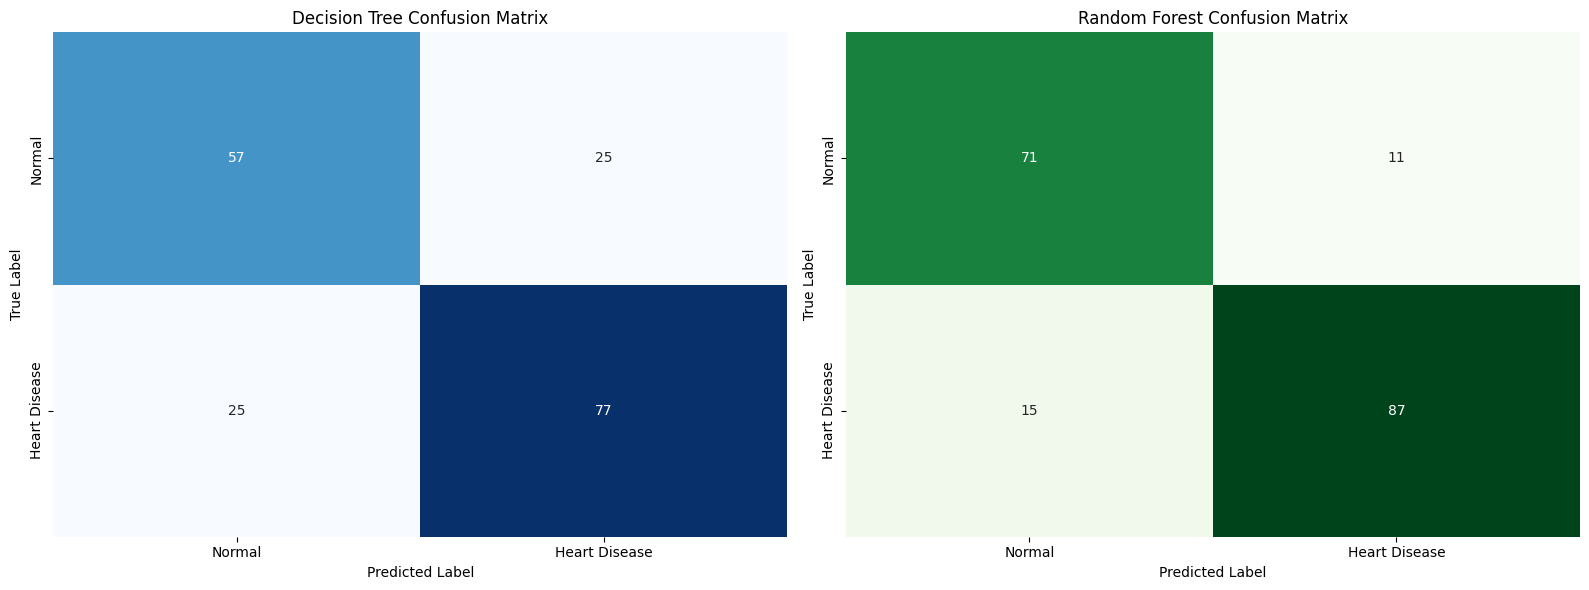

In [9]:
# 2. Side-by-side confusion matrices for clinical error analysis.
cm_dt = confusion_matrix(y_test, y_pred_dt)
cm_rf = confusion_matrix(y_test, y_pred_rf)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="g",
    cmap="Blues",
    cbar=False,
    ax=axes[0],
    xticklabels=["Normal", "Heart Disease"],
    yticklabels=["Normal", "Heart Disease"],
)
axes[0].set_title("Decision Tree Confusion Matrix")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="g",
    cmap="Greens",
    cbar=False,
    ax=axes[1],
    xticklabels=["Normal", "Heart Disease"],
    yticklabels=["Normal", "Heart Disease"],
)
axes[1].set_title("Random Forest Confusion Matrix")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

plt.tight_layout()
plt.show()

In [10]:
# 3. Print detailed classification reports to review class-specific precision, recall, and F1 scores.
print("--- Decision Tree Classification Report ---")
print(classification_report(y_test, y_pred_dt, target_names=["Normal", "Heart Disease"]))
print("--- Random Forest Classification Report ---")
print(classification_report(y_test, y_pred_rf, target_names=["Normal", "Heart Disease"]))

--- Decision Tree Classification Report ---
               precision    recall  f1-score   support

       Normal       0.70      0.70      0.70        82
Heart Disease       0.75      0.75      0.75       102

     accuracy                           0.73       184
    macro avg       0.73      0.73      0.73       184
 weighted avg       0.73      0.73      0.73       184

--- Random Forest Classification Report ---
               precision    recall  f1-score   support

       Normal       0.83      0.87      0.85        82
Heart Disease       0.89      0.85      0.87       102

     accuracy                           0.86       184
    macro avg       0.86      0.86      0.86       184
 weighted avg       0.86      0.86      0.86       184



--------------------------------

### ***PHASE 5: Model Interpretability & Feature Importance***
- Translate the trained models into clinically actionable insights by visualizing the decision tree, extracting its rules, and comparing feature importances.

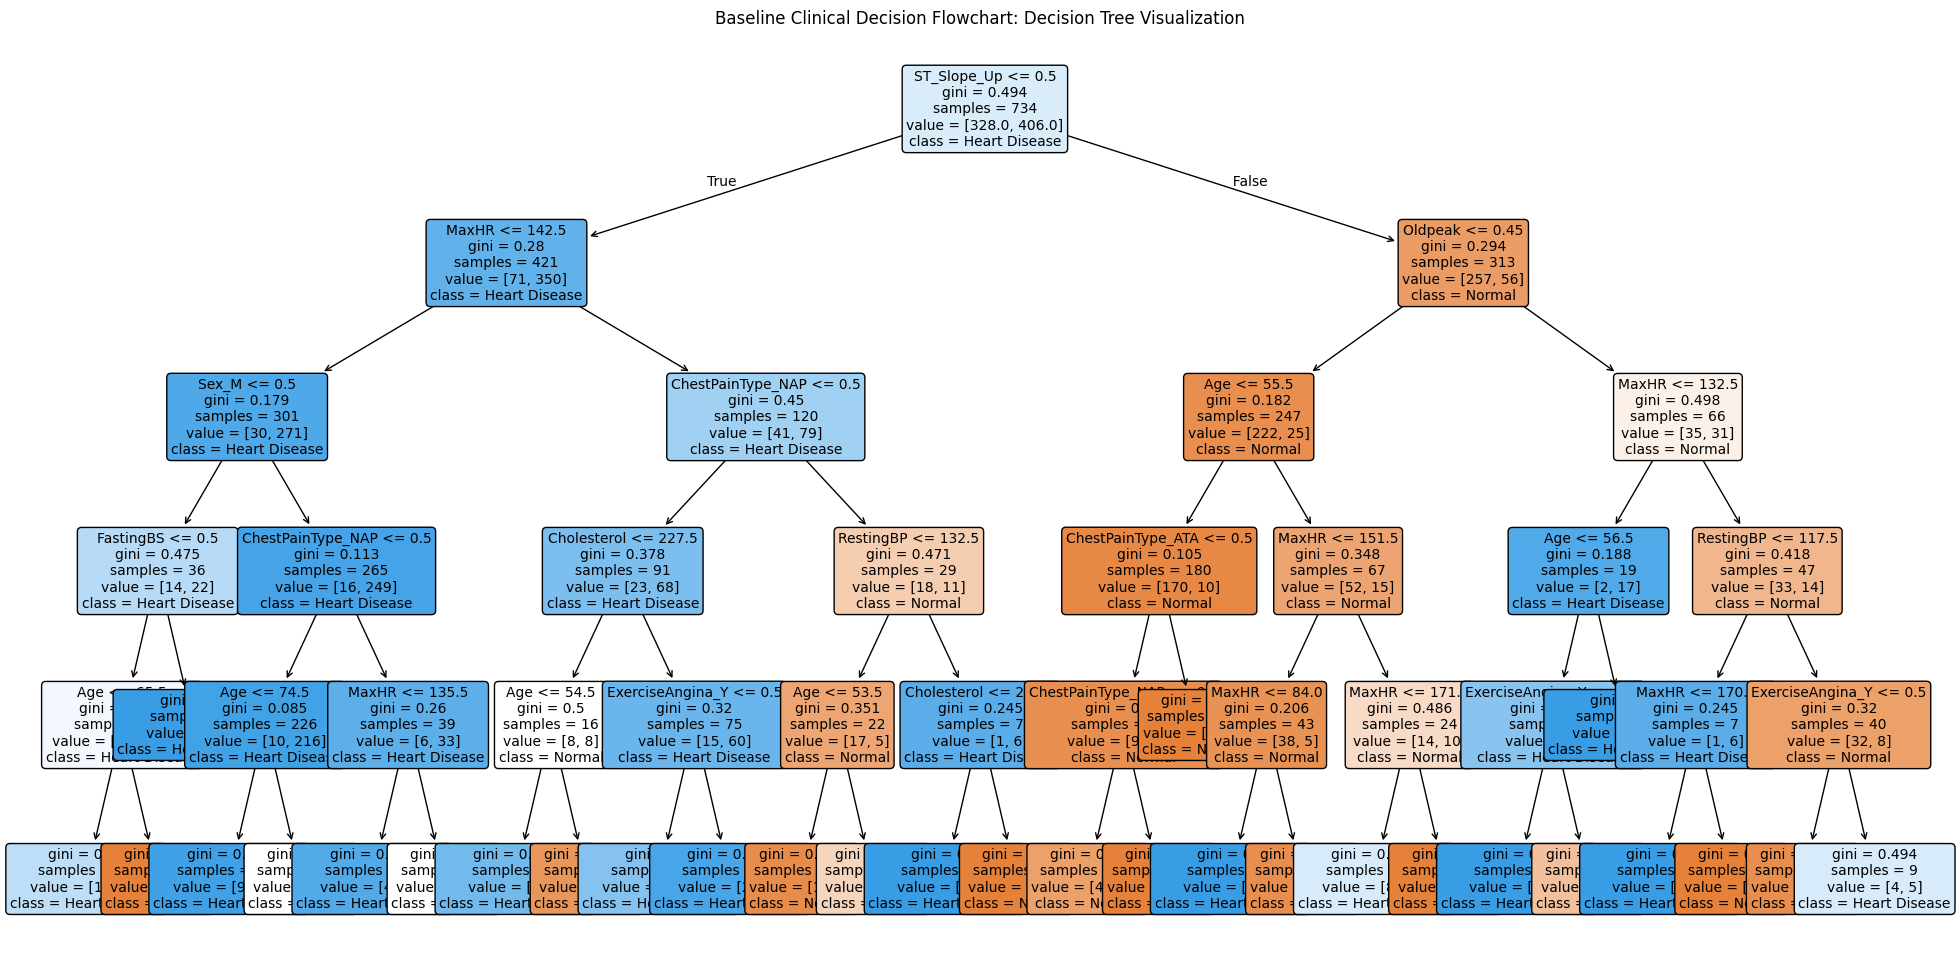

In [11]:
# 1. Decision Tree Visualization (The Clinical Flowchart)
plt.figure(figsize=(24, 12))
plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=["Normal", "Heart Disease"],
    filled=True,
    rounded=True,
    fontsize=10,
)
plt.title("Baseline Clinical Decision Flowchart: Decision Tree Visualization")
plt.show()

In [12]:
# 2. Extracting Highly Readable Clinical Rules
print("--- Decision Tree Rules: Transparent Clinical If-Then Logic ---")
print(
    "The following rules represent the explicit decision logic used by the tree. "
    "These can be communicated to clinicians as transparent, data-driven guidance."
)
rule_text = export_text(dt_model, feature_names=list(X.columns))
print(rule_text)

--- Decision Tree Rules: Transparent Clinical If-Then Logic ---
The following rules represent the explicit decision logic used by the tree. These can be communicated to clinicians as transparent, data-driven guidance.
|--- ST_Slope_Up <= 0.50
|   |--- MaxHR <= 142.50
|   |   |--- Sex_M <= 0.50
|   |   |   |--- FastingBS <= 0.50
|   |   |   |   |--- Age <= 65.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- Age >  65.50
|   |   |   |   |   |--- class: 0
|   |   |   |--- FastingBS >  0.50
|   |   |   |   |--- class: 1
|   |   |--- Sex_M >  0.50
|   |   |   |--- ChestPainType_NAP <= 0.50
|   |   |   |   |--- Age <= 74.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- Age >  74.50
|   |   |   |   |   |--- class: 0
|   |   |   |--- ChestPainType_NAP >  0.50
|   |   |   |   |--- MaxHR <= 135.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- MaxHR >  135.50
|   |   |   |   |   |--- class: 0
|   |--- MaxHR >  142.50
|   |   |--- ChestPainType_NAP <= 0.50
|   |   |   |-

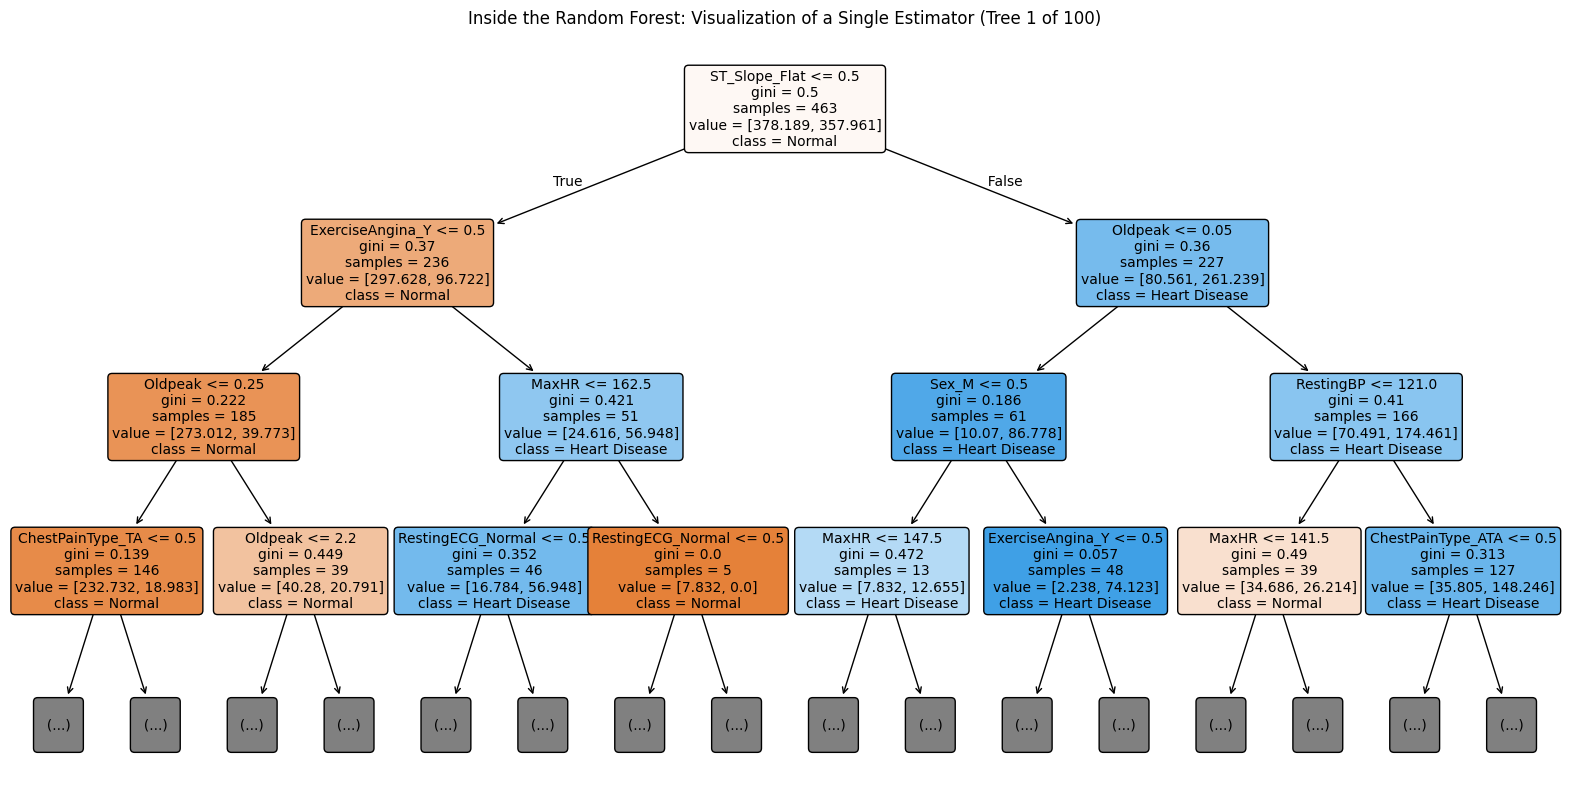

In [13]:
# 3. Random Forest Tree Visualization (Ensemble Illustration)
# Show one estimator from the forest to illustrate how the ensemble builds diverse trees.
single_rf_tree = rf_model.estimators_[0]

plt.figure(figsize=(20, 10))
plot_tree(
    single_rf_tree,
    feature_names=X.columns,
    class_names=["Normal", "Heart Disease"],
    filled=True,
    rounded=True,
    fontsize=10,
    max_depth=3,
)
plt.title("Inside the Random Forest: Visualization of a Single Estimator (Tree 1 of 100)")
plt.show()

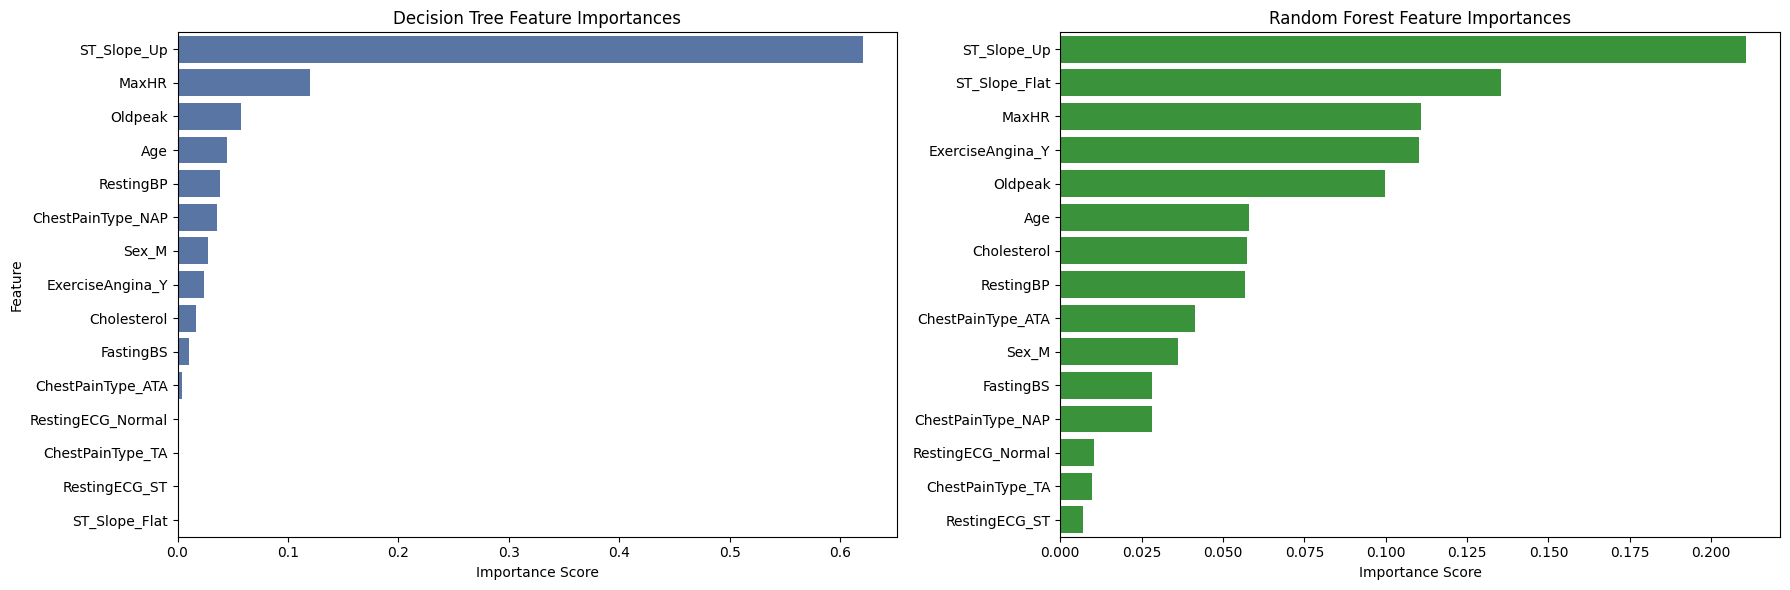

In [14]:
# 4. Feature Importance Comparison (Validating Risk Archetypes)
# Extract the learned importance scores from both models.
dt_importances = dt_model.feature_importances_
rf_importances = rf_model.feature_importances_

importance_df = pd.DataFrame(
    {
        "feature": X.columns,
        "Decision Tree Importance": dt_importances,
        "Random Forest Importance": rf_importances,
    }
)

# Sort importances in descending order for both models.
dt_sorted = importance_df.sort_values(by="Decision Tree Importance", ascending=False)
rf_sorted = importance_df.sort_values(by="Random Forest Importance", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.barplot(
    x="Decision Tree Importance",
    y="feature",
    data=dt_sorted,
    ax=axes[0],
    color="#4c72b0",
)
axes[0].set_title("Decision Tree Feature Importances")
axes[0].set_xlabel("Importance Score")
axes[0].set_ylabel("Feature")

sns.barplot(
    x="Random Forest Importance",
    y="feature",
    data=rf_sorted,
    ax=axes[1],
    color="#2ca02c",
)
axes[1].set_title("Random Forest Feature Importances")
axes[1].set_xlabel("Importance Score")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

--------------------------------

### ***PHASE 6: Clinical Risk Scoring (The Business Application)***
- Use the Random Forest output to translate predictions into patient risk tiers and prioritized clinical action lists for hospital workflows.

In [15]:
# 1. Construct the Patient Risk DataFrame
patient_risk_df = X_test.reset_index(drop=True).copy()
patient_risk_df["True_Status"] = y_test.reset_index(drop=True)
patient_risk_df["Heart_Disease_Probability_Score"] = y_proba_rf
patient_risk_df["Heart_Disease_Probability"] = (
    patient_risk_df["Heart_Disease_Probability_Score"].map("{:.1%}".format)
)
patient_risk_df["Predicted_Status"] = y_pred_rf

# Keep the numeric score for risk tier logic while showing the readable percentage.
patient_risk_df = patient_risk_df[
    [
        *X_test.columns.tolist(),
        "True_Status",
        "Predicted_Status",
        "Heart_Disease_Probability_Score",
        "Heart_Disease_Probability",
    ]
]

print("--- Patient Risk DataFrame Created ---")
print(patient_risk_df.head(3))
print("\n")

--- Patient Risk DataFrame Created ---
   Age  RestingBP  Cholesterol  FastingBS  MaxHR  Oldpeak  Sex_M  \
0   46      115.0        237.0          0    113      1.5      1   
1   58      132.0        224.0          0    173      3.2      1   
2   60      125.0        258.0          0    141      2.8      1   

   ChestPainType_ATA  ChestPainType_NAP  ChestPainType_TA  RestingECG_Normal  \
0                  0                  0                 0                  1   
1                  0                  1                 0                  0   
2                  0                  0                 0                  0   

   RestingECG_ST  ExerciseAngina_Y  ST_Slope_Flat  ST_Slope_Up  True_Status  \
0              0                 1              1            0            1   
1              0                 0              0            1            1   
2              0                 1              1            0            1   

   Predicted_Status  Heart_Disease_Probability_Sco

In [16]:
# 2. Implement Clinical Risk Stratification (Tiers)
risk_conditions = [
    patient_risk_df["Heart_Disease_Probability_Score"] < 0.40,
    patient_risk_df["Heart_Disease_Probability_Score"].between(0.40, 0.69),
    patient_risk_df["Heart_Disease_Probability_Score"] >= 0.70,
]
risk_choices = ["Low Risk", "Medium Risk", "High Risk"]

patient_risk_df["Risk_Tier"] = np.select(risk_conditions, risk_choices, default="Low Risk")

print("--- Risk Tier Distribution ---")
print(patient_risk_df["Risk_Tier"].value_counts())
print("\n")

--- Risk Tier Distribution ---
Risk_Tier
High Risk      79
Low Risk       75
Medium Risk    30
Name: count, dtype: int64




In [17]:
# 3. Generate the "Immediate Action" Triage List
high_risk_list = patient_risk_df.sort_values(
    by="Heart_Disease_Probability_Score", ascending=False
)

print("🏥 TOP 10 HIGHEST RISK PATIENTS (Immediate Clinical Intervention Required):")
print(high_risk_list.head(10).to_string(index=False))
print("\n")

🏥 TOP 10 HIGHEST RISK PATIENTS (Immediate Clinical Intervention Required):
 Age  RestingBP  Cholesterol  FastingBS  MaxHR  Oldpeak  Sex_M  ChestPainType_ATA  ChestPainType_NAP  ChestPainType_TA  RestingECG_Normal  RestingECG_ST  ExerciseAngina_Y  ST_Slope_Flat  ST_Slope_Up  True_Status  Predicted_Status  Heart_Disease_Probability_Score Heart_Disease_Probability Risk_Tier
  57      139.0        277.0          1    118      1.9      1                  0                  0                 0                  0              1                 1              1            0            1                 1                         0.983167                     98.3% High Risk
  58      136.0        203.0          1    123      1.2      1                  0                  0                 0                  1              0                 1              1            0            1                 1                         0.966587                     96.7% High Risk
  56      137.0        282.0

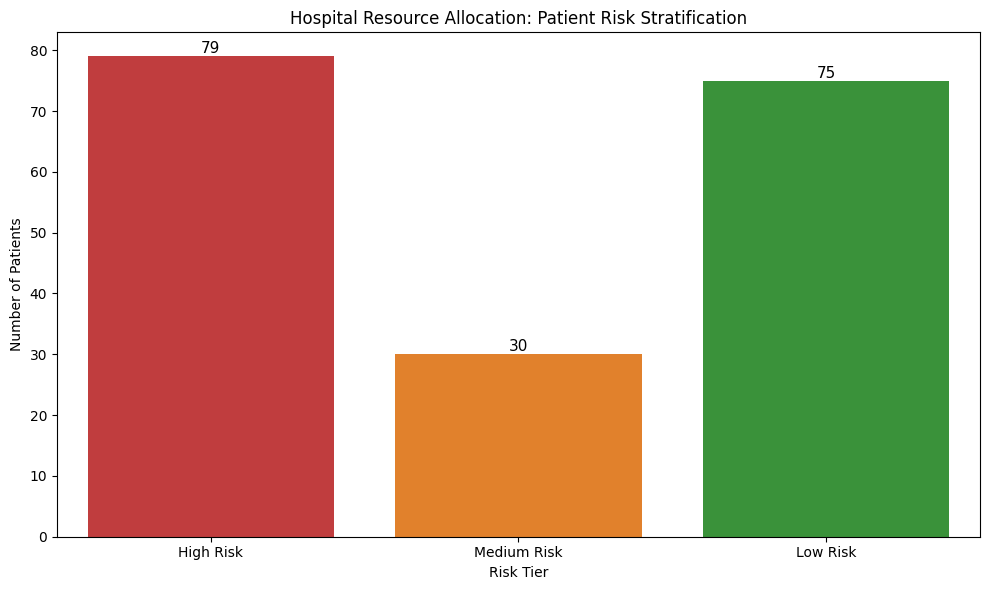

In [18]:
# 4. Visualize the Clinical Workload (Resource Allocation)
plt.figure(figsize=(10, 6))
order = ["High Risk", "Medium Risk", "Low Risk"]
palette = {"Low Risk": "#2ca02c", "Medium Risk": "#ff7f0e", "High Risk": "#d62728"}
ax = sns.countplot(
    data=patient_risk_df,
    x="Risk_Tier",
    hue="Risk_Tier",
    order=order,
    palette=palette,
    legend=False,
)
ax.set_title("Hospital Resource Allocation: Patient Risk Stratification")
ax.set_xlabel("Risk Tier")
ax.set_ylabel("Number of Patients")

for p in ax.patches:
    count = int(p.get_height())
    ax.annotate(
        f"{count}",
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha="center",
        va="bottom",
        fontsize=11,
        color="black",
    )

plt.tight_layout()
plt.show()